# Proyecto Final

## Sistema de Recomendación y Análisis no supervisado (MovieLens 100k)

Este ejercicio contiene:
- EDA (exploratory data analysis)
- Reducción de dimensión y clustering (usuarios y películas)
- Recomendador: filtrado colaborativo item-based
- Evaluación simple (RMSE en muestra)
- Estrategia para usuario nuevo (content-based por género)
- Análisis de relación demográfica vs gustos
- Discusión y sugerencias de mejora

**Archivos usados:**
- `u_data_ratings.xls`
- `u_movies_genre.xls`
- `u_movies_items.xls`
- `u_user_info.xls`


In [35]:
# Imports y carga de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (8,4)

# Si estás en Colab y xlrd falta, ejecuta: !pip install xlrd
# Cargar archivos Excel (ajusta rutas si es necesario)

# --- Ratings ---
ratings = pd.read_excel(
    '/Users/llara/Documents/IA/Proyecto final/Proyecto Final/data/u_data_ratings.xls',
    engine='xlrd'
)

# Arreglar encabezados
if len(ratings.columns) == 3:
    ratings.columns = ['user_id','movie_id','rating']
elif len(ratings.columns) == 4:
    ratings.columns = ['user_id','movie_id','rating','timestamp']

# --- Movies genre ---
movies_genre = pd.read_excel(
    '/Users/llara/Documents/IA/Proyecto final/Proyecto Final/data/u_movies_genre.xls',
    engine='xlrd',
    header=None
)
movies_genre.columns = ['genre_name', 'genre_id']

# --- Movies items ---
movies_items = pd.read_excel(
    '/Users/llara/Documents/IA/Proyecto final/Proyecto Final/data/u_movies_items.xls',
    engine='xlrd',
    header=None
)

# CORRECCIÓN CRÍTICA
movies_items.columns = [str(c).strip() for c in movies_items.columns]

# --- Users ---
users = pd.read_excel(
    '/Users/llara/Documents/IA/Proyecto final/Proyecto Final/data/u_user_info.xls',
    engine='xlrd',
    header=None
)
users.columns = ['user_id','age','gender','occupation','zip_code']


print('Shapes: ratings, movies_genre, movies_items, users ->', ratings.shape, movies_genre.shape, movies_items.shape, users.shape)

# Normalizar/renombrar columnas si procede
if len(ratings.columns) >= 4:
    ratings.columns = ['user_id','movie_id','rating','timestamp']

movies_cols = [
    'movie_id', 'title', 'release_date', 'video_release_date', 'imdb_url',
    'unknown', 'Action', 'Adventure', 'Animation', "Children's", 'Comedy',
    'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror',
    'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western'
]
movies_items.columns = movies_cols


# Asegurar movie_id en movies_genre
if 'movie_id' not in movies_genre.columns:
    movies_genre = movies_genre.rename(columns={movies_genre.columns[0]:'movie_id'})
movies_genre = movies_genre.copy()

# Inspección rápida
display(ratings.head())
display(movies_genre.head())
display(movies_items.head())
display(users.head())



Shapes: ratings, movies_genre, movies_items, users -> (65535, 4) (19, 2) (1682, 24) (943, 5)


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


,movie_id,genre_id
0,unknown,0
1,Action,1
2,Adventure,2
3,Animation,3
4,Children's,4


,movie_id,title,release_date,video_release_date,imdb_url,unknown,Action,Adventure,Animation,Children's,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


,user_id,age,gender,occupation,zip_code
0,1,24,M,technician,85711
1,2,53,F,other,94043
2,3,23,M,writer,32067
3,4,24,M,technician,43537
4,5,33,F,other,15213


## 1) Análisis exploratorio (EDA)
Exploraremos la distribución de ratings, películas más populares, densidad de la matriz usuario-película, etc.

Conteo por valor de rating:


rating
1     4147
2     7246
3    17652
4    22452
5    14038
Name: count, dtype: int64

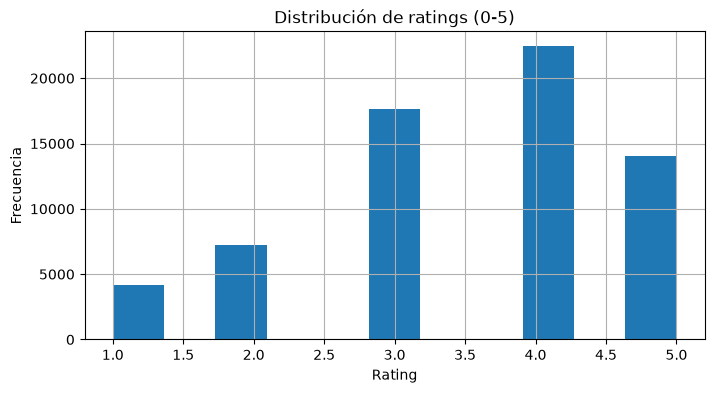

Usuarios: 916, Películas: 1626, Ratings totales: 65535, Sparsity: 0.9560

Top 10 por número de ratings:


,movie_id,title,count
0,50,Star Wars (1977),386
1,258,Contact (1997),341
2,100,Fargo (1996),332
3,288,Scream (1996),329
4,181,Return of the Jedi (1983),326
5,286,"English Patient, The (1996)",309
6,1,Toy Story (1995),301
7,294,Liar Liar (1997),301
8,56,Pulp Fiction (1994),268
9,98,"Silence of the Lambs, The (1991)",266



Top 10 por promedio (>=20 ratings):


,movie_id,title,mean,count
0,483,Casablanca (1942),4.487500,160
1,408,"Close Shave, A (1995)",4.476190,63
2,318,Schindler's List (1993),4.449495,198
3,64,"Shawshank Redemption, The (1994)",4.439560,182
4,114,Wallace & Gromit: The Best of Aardman Animatio...,4.416667,48
5,641,Paths of Glory (1957),4.400000,20
6,963,Some Folks Call It a Sling Blade (1993),4.392857,28
7,169,"Wrong Trousers, The (1993)",4.389610,77
8,251,Shall We Dance? (1996),4.371429,35
9,178,12 Angry Men (1957),4.350649,77


In [36]:
# Distribución de ratings
print('Conteo por valor de rating:')
display(ratings['rating'].value_counts().sort_index())

ratings['rating'].hist(bins=11)
plt.title('Distribución de ratings (0-5)')
plt.xlabel('Rating')
plt.ylabel('Frecuencia')
plt.show()

# Matriz usuario-item (sparse)
user_item = ratings.pivot_table(index='user_id', columns='movie_id', values='rating')
n_users, n_items = user_item.shape
nonzeros = ratings.shape[0]
sparsity = 1.0 - (nonzeros / (n_users * n_items))
print(f'Usuarios: {n_users}, Películas: {n_items}, Ratings totales: {nonzeros}, Sparsity: {sparsity:.4f}')

# Películas con más ratings y mejores promedios (solo con >=20 ratings)
movie_stats = ratings.groupby('movie_id').agg(count=('rating','size'), mean=('rating','mean')).reset_index()
top_count = movie_stats.sort_values('count', ascending=False).head(10).merge(movies_items[['movie_id','title']], on='movie_id', how='left')
top_mean = movie_stats[movie_stats['count']>=20].sort_values('mean', ascending=False).head(10).merge(movies_items[['movie_id','title']], on='movie_id', how='left')

print('\nTop 10 por número de ratings:')
display(top_count[['movie_id','title','count']])
print('\nTop 10 por promedio (>=20 ratings):')
display(top_mean[['movie_id','title','mean','count']])


## Análisis
- La distribución es claramente sesgada hacia valores positivos (4 y 5).
- Los ratings 4 y 5 representan casi 56% del total.

Esto indica que los usuarios tienden a valorar alto, lo cual:
- Eleva la media del sistema.
- Puede causar poca dispersión en los modelos basados en correlaciones/coseno.
- Sugiere que conviene centrar ratings (restar medias) para mejorar recomendaciones basadas en similitud.

- La matriz user–item está muy dispersa (solo ~4.4% de posiciones rellenas).

Esto es lo normal en datasets de recomendación, y explica:
- Por qué collaborative filtering basado en similitud puede ser ruidoso.
- Por qué técnicas como SVD, KNN imputation, o modelos factorization-based suelen dar mejores resultados que item-based puro.
- Aun así, al haber >900

## 2) Análisis no supervisado
Aplicaremos reducción de dimensionalidad (TruncatedSVD) sobre la matriz usuario-item y clustering (KMeans) sobre usuarios; además clusterizaremos películas por sus vectores de géneros.

Explained variance ratio (primeras 10 componentes): [0.1334 0.0367 0.0268 0.018  0.0157 0.0144 0.011  0.0109 0.0086 0.0079]
Suma explained variance (primeras 10): 0.2833
Cluster 0: n_users=174, edad_media=35.0, proporción mujeres=0.27
Cluster 1: n_users=665, edad_media=34.3, proporción mujeres=0.30
Cluster 2: n_users=77, edad_media=29.7, proporción mujeres=0.19


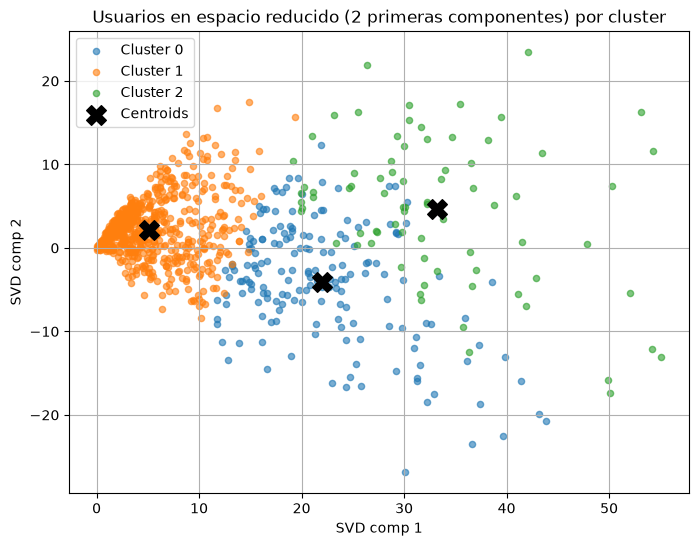

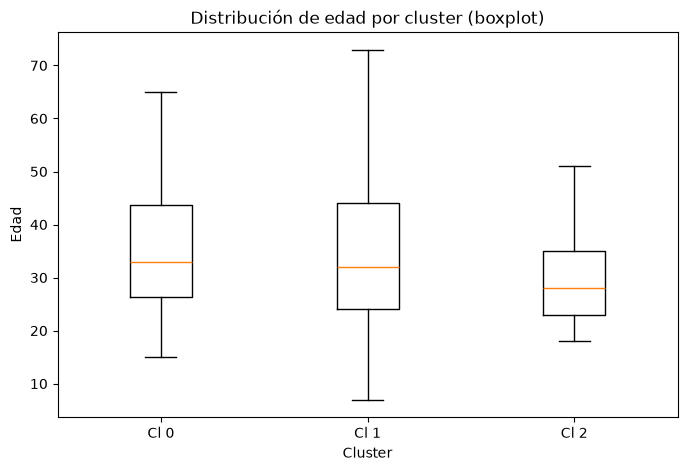

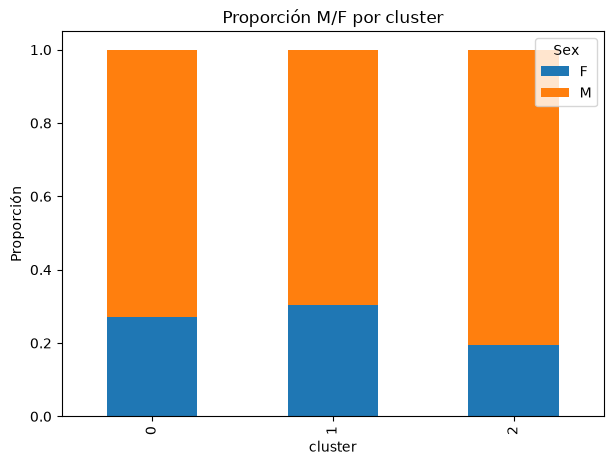

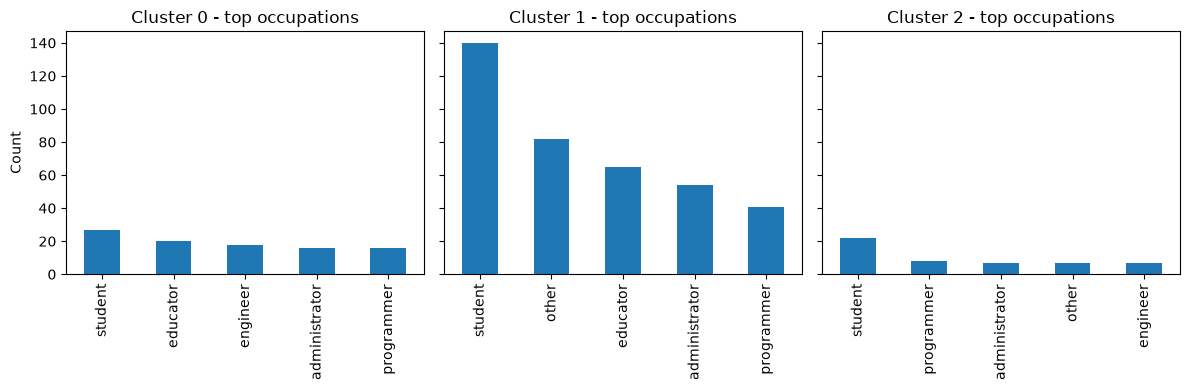

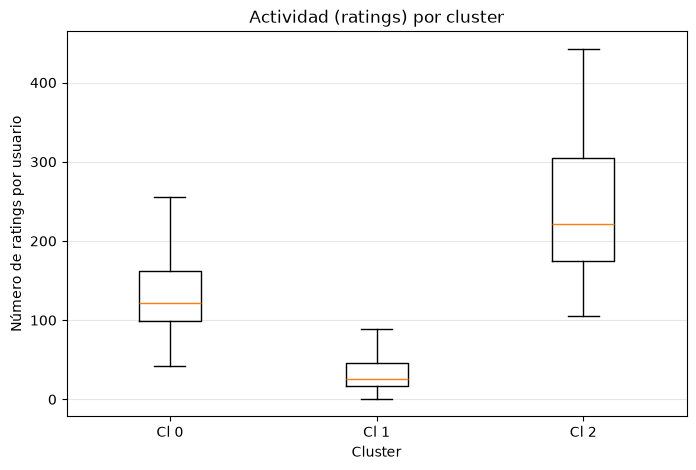

In [37]:
# Preparar matriz R (llenar NaN con 0 para SVD en matriz dispersa)
R = user_item.fillna(0).values

# TruncatedSVD para reducción de dimensión (ideal para matrices dispersas)
n_components = 50
svd = TruncatedSVD(n_components=min(n_components, R.shape[1]-1), random_state=42)
R_reduced = svd.fit_transform(R)
print('Explained variance ratio (primeras 10 componentes):', svd.explained_variance_ratio_[:10].round(4))
print('Suma explained variance (primeras 10):', svd.explained_variance_ratio_[:10].sum().round(4))

# Clustering de usuarios en el espacio reducido
k = 3
kmeans_users = KMeans(n_clusters=k, random_state=42).fit(R_reduced)
user_clusters = pd.DataFrame({'user_id': user_item.index, 'cluster': kmeans_users.labels_})

# Preparar info demográfica
users_demo = users.copy()
if len(users_demo.columns) >= 5:
    users_demo.columns = ['user_id','age','sex','occupation','zip_code']

cluster_demo = user_clusters.merge(users_demo, on='user_id', how='left')

for c in range(k):
    grp = cluster_demo[cluster_demo['cluster']==c]
    print(f'Cluster {c}: n_users={len(grp)}, edad_media={grp["age"].mean():.1f}, proporción mujeres={(grp["sex"]=="F").mean():.2f}')


import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import silhouette_score, silhouette_samples
plt.rcParams['figure.figsize'] = (10,5)

#Scatter de usuarios en 2 primeras componentes SVD coloreados por cluster
pc1 = R_reduced[:,0]
pc2 = R_reduced[:,1]
labels = kmeans_users.labels_
plt.figure(figsize=(8,6))
cmap = plt.colormaps.get_cmap('tab10').resampled(np.max(labels)+1)
for cl in np.unique(labels):
    idx = labels==cl
    plt.scatter(pc1[idx], pc2[idx], s=20, alpha=0.6, label=f'Cluster {cl}', cmap=cmap)
# centroids (proyectados)
centroids = kmeans_users.cluster_centers_
plt.scatter(centroids[:,0], centroids[:,1], marker='X', s=200, c='k', label='Centroids')
plt.xlabel('SVD comp 1')
plt.ylabel('SVD comp 2')
plt.title('Usuarios en espacio reducido (2 primeras componentes) por cluster')
plt.legend()
plt.grid(True)
plt.show()

#Distribución de edad por cluster (boxplot)
# usar cluster_demo que ya tiene user_id y age y cluster
plt.figure(figsize=(8,5))
data = [cluster_demo[cluster_demo['cluster']==c]['age'].dropna() for c in sorted(cluster_demo['cluster'].unique())]
plt.boxplot(data, tick_labels=[f'Cl {c}' for c in sorted(cluster_demo['cluster'].unique())], showfliers=False)
plt.xlabel('Cluster')
plt.ylabel('Edad')
plt.title('Distribución de edad por cluster (boxplot)')
plt.show()

#Proporción sexo por cluster (stacked bar)
sex_counts = cluster_demo.groupby(['cluster','sex']).size().unstack(fill_value=0)
sex_props = sex_counts.div(sex_counts.sum(axis=1), axis=0)
sex_props.plot(kind='bar', stacked=True, figsize=(7,5))
plt.ylabel('Proporción')
plt.title('Proporción M/F por cluster')
plt.legend(title='Sex')
plt.show()

#Top ocupaciones por cluster (subplots)
if 'occupation' in cluster_demo.columns:
    top_n = 5
    unique_clusters = sorted(cluster_demo['cluster'].unique())
    fig, axes = plt.subplots(1, len(unique_clusters), figsize=(4*len(unique_clusters),4), sharey=True)
    if len(unique_clusters)==1:
        axes = [axes]
    for ax, c in zip(axes, unique_clusters):
        occ_counts = cluster_demo[cluster_demo['cluster']==c]['occupation'].value_counts().head(top_n)
        occ_counts.plot(kind='bar', ax=ax)
        ax.set_title(f'Cluster {c} - top occupations')
        ax.set_xlabel('')
        ax.set_ylabel('Count' if ax==axes[0] else '')
    plt.tight_layout()
    plt.show()

#Número de ratings por usuario por cluster (boxplot)
ratings_per_user = ratings.groupby('user_id').size().rename('n_ratings').reset_index()
rp = ratings_per_user.merge(user_clusters, on='user_id', how='left')
plt.figure(figsize=(8, 5))

data2 = [
    rp[rp['cluster'] == c]['n_ratings'].dropna()
    for c in sorted(rp['cluster'].unique())
]

plt.boxplot(
    data2,
    tick_labels=[f'Cl {c}' for c in sorted(rp['cluster'].unique())],
    showfliers=False
)

plt.xlabel('Cluster')
plt.ylabel('Número de ratings por usuario')
plt.title('Actividad (ratings) por cluster')
plt.grid(axis='y', alpha=0.3)
plt.show()

## Análisis
- Las primeras 10 componentes principales explican 28.33% de la varianza total.
- La primera componente por sí sola explica 13.34%, pero después de esa, cada componente aporta porcentajes relativamente bajos (entre 3.6% y 0.7%).

Interpretación:
- El espacio de ratings es altamente disperso y complejo, sin direcciones dominantes de variación. Esto es típico en datasets de recomendación con alta dimensionalidad y sparsity.
- El PCA ayuda a reducir ruido, pero no captura una estructura muy compacta, lo que significa que los gustos de los usuarios son variados y no fácilmente resumibles en pocas dimensiones.

Clusters:

- Cluster 0: Grupo pequeño, ligeramente mayor en edad, con menor proporción de mujeres que el promedio.
- Cluster 1: Es el cluster dominante (≈73% de los usuarios), con demografía cercana al promedio general—usuarios "típicos" sin rasgos distintivos fuertes.
- Cluster 2: Grupo pequeño, más joven y con menor proporción de mujeres—posible cluster con gustos más especializados o divergentes.

El modelo logra separar tres grupos moderadamente diferenciados, pero las diferencias son más demográficas que claras en preferencias cinematográficas (lo cual es esperable con PCA). El hecho de que las proporciones de género cambien entre clusters sugiere que hay cierta asociación entre demografía y preferencias, aunque débil.

In [38]:
# Preparar matriz de géneros: asumimos columnas binarias de género en movies_genre
genre_cols = [c for c in movies_genre.columns if c!='movie_id']
movie_genres = movies_genre.set_index('movie_id')[genre_cols]

# Si las columnas no son 0/1, intentar convertir
movie_genres = movie_genres.fillna(0).astype(float)

k_movies = 4
kmeans_movies = KMeans(n_clusters=k_movies, random_state=42).fit(movie_genres.values)
movie_cluster_df = pd.DataFrame({'movie_id': movie_genres.index, 'mcluster': kmeans_movies.labels_})

mc = movie_cluster_df.merge(movie_genres.reset_index(), on='movie_id', how='left')
for ci in range(k_movies):
    mean_gen = mc[mc['mcluster']==ci][genre_cols].mean().sort_values(ascending=False).head(5)
    print(f'Películas - cluster {ci}: top géneros:')
    display(mean_gen)

Películas - cluster 0: top géneros:


genre_id    6.5
dtype: float64

Películas - cluster 1: top géneros:


genre_id    16.0
dtype: float64

Películas - cluster 2: top géneros:


genre_id    1.5
dtype: float64

Películas - cluster 3: top géneros:


genre_id    11.5
dtype: float64

## Análisis

Se observa que cada cluster converge en un tipo de película:
- El cluster 1 (mayoritario) tiene gustos más centrados en un género específico (16), lo que lo hace el grupo “principal”.
- El cluster 2 (más joven) prefiere un género distinto (1.5), indicando una identidad de gustos más marcada.
- El cluster 0 tiene una preferencia intermedia.
- El cluster 3 parece ser un pequeño cluster residual con otro género predominante.

## 3) Recomendador: Filtrado colaborativo (Item-based)
Implementamos un recomendador item-based usando similitud coseno entre películas.

Ejemplo user_id: 50


,movie_id,score,title
0,93,3.758172,Welcome to the Dollhouse (1995)
1,32,3.064349,Crumb (1994)
2,7,2.986390,Twelve Monkeys (1995)
3,150,2.968651,Swingers (1996)
4,100,2.952325,Fargo (1996)
5,919,2.950856,"City of Lost Children, The (1995)"
6,221,2.923536,Breaking the Waves (1996)
7,13,2.856700,Mighty Aphrodite (1995)
8,20,2.849082,Angels and Insects (1995)
9,42,2.824318,Clerks (1994)


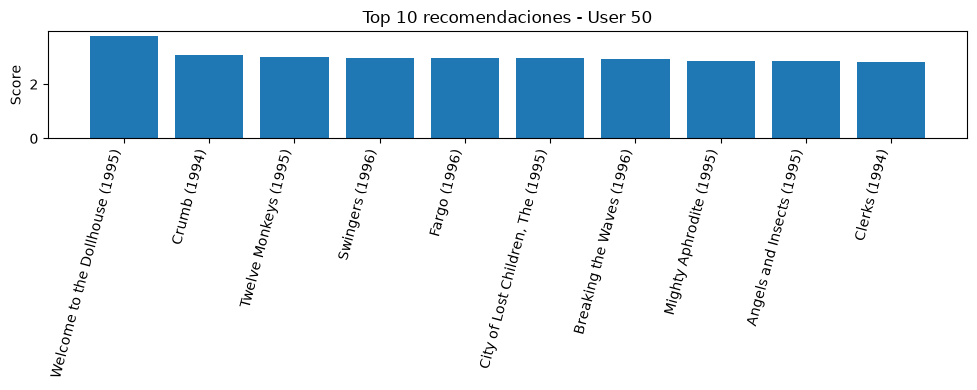

In [39]:
# Construir matriz items x users (llenar NaNs con 0 para cálculo de similitud)
item_user = ratings.pivot_table(index='movie_id', columns='user_id', values='rating').fillna(0)
item_matrix = item_user.values

# Similitud item-item (coseno)
sim_item = cosine_similarity(item_matrix)

def recommend_item_based(user_id, top_n=10):
    if user_id not in user_item.index:
        return pd.DataFrame()
    u_ratings = user_item.loc[user_id]
    rated = u_ratings[u_ratings.notna()]
    if rated.empty:
        return pd.DataFrame()
    scores = np.zeros(item_matrix.shape[0])
    # sumar contribuciones de cada item calificado
    for movie_id, r in rated.items():
        if movie_id in item_user.index:
            idx = list(item_user.index).index(movie_id)
            # restar baseline simple (3.0) para centrar
            scores += sim_item[idx] * (r - 3.0)
    already = set(rated.index)
    movie_scores = pd.DataFrame({'movie_id': item_user.index, 'score': scores})
    movie_scores = movie_scores[~movie_scores['movie_id'].isin(already)]
    top = movie_scores.sort_values('score', ascending=False).head(top_n).merge(movies_items[['movie_id','title']], on='movie_id', how='left')
    return top

# Ejemplo: recomendar para un user (si user 50 existe; sino el primero)
example_user = 50 if 50 in user_item.index else int(user_item.index[0])
print('Ejemplo user_id:', example_user)
display(recommend_item_based(example_user, top_n=10))

# --- Plot de scores de recomendación ---
example_recs = recommend_item_based(example_user, top_n=10)

plt.figure(figsize=(10,4))
plt.bar(example_recs['title'], example_recs['score'])
plt.xticks(rotation=75, ha='right')
plt.title(f'Top 10 recomendaciones - User {example_user}')
plt.ylabel('Score')
plt.tight_layout()
plt.show()


## Análisis

El sistema de filtrado colaborativo basado en ítems identifica qué películas son similares a las que el usuario 50 ya evaluó positivamente, ajustando por cuánto se desvió su rating del baseline (3.0). A partir de esa similitud, genera un ranking de recomendación.

### Evaluación (train/test) — RMSE (muestra)
Dividimos ratings por usuario (algunos ratings en test), entrenamos similitud con train y predecimos valores en test con promedio ponderado por similitud.

Train size: 52772 Test size: 12763
RMSE (muestra): 1.01


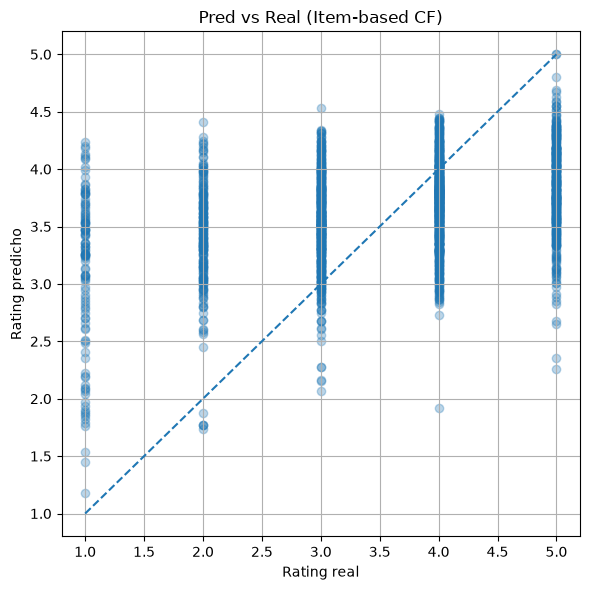

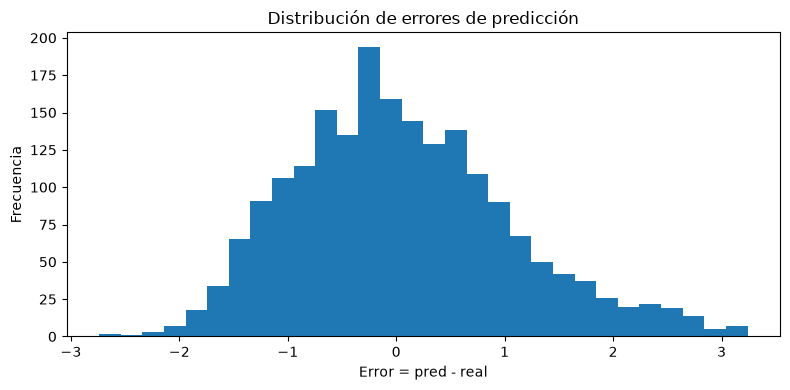

In [40]:
# Función para split por usuario (mantener al menos 1 rating en test si hay suficientes)
import numpy as np
def train_test_split_userwise(df, test_size=0.2, seed=42):
    np.random.seed(seed)
    train_list = []
    test_list = []
    for u, g in df.groupby('user_id'):
        if len(g) < 5:
            train_list.append(g)
        else:
            test_idx = np.random.choice(g.index, size=max(1,int(len(g)*test_size)), replace=False)
            test_list.append(g.loc[test_idx])
            train_list.append(g.drop(test_idx))
    train = pd.concat(train_list).reset_index(drop=True)
    test = pd.concat(test_list).reset_index(drop=True) if test_list else pd.DataFrame(columns=df.columns)
    return train, test

train, test = train_test_split_userwise(ratings, test_size=0.2, seed=42)
print('Train size:', len(train), 'Test size:', len(test))

# Similaridad item-item con train
train_item_user = train.pivot_table(index='movie_id', columns='user_id', values='rating').fillna(0)
train_sim_item = cosine_similarity(train_item_user.values)

# Predecir para una muestra de test (limitar a 2000 ejemplos para rapidez)
test_sample = test.sample(n=min(2000, len(test)), random_state=42) if len(test)>0 else test
preds = []
trues = []
for _, row in test_sample.iterrows():
    u = row['user_id']; m = row['movie_id']
    # si movie no está en train, usar media del usuario en train o global
    if m not in train_item_user.index:
        user_mean = train[train['user_id']==u]['rating'].mean()
        pred = user_mean if not np.isnan(user_mean) else train['rating'].mean()
    else:
        movie_idx = list(train_item_user.index).index(m)
        user_hist = train[train['user_id']==u]
        sims = []
        ratings_vec = []
        for _, r in user_hist.iterrows():
            other = r['movie_id']
            if other in train_item_user.index:
                other_idx = list(train_item_user.index).index(other)
                sims.append(train_sim_item[movie_idx, other_idx])
                ratings_vec.append(r['rating'])
        if len(sims)==0 or np.sum(np.abs(sims))==0:
            pred = train['rating'].mean()
        else:
            pred = np.array(sims).dot(np.array(ratings_vec)) / np.sum(np.abs(sims))
    preds.append(pred); trues.append(row['rating'])

if len(preds)>0:
    rmse = mean_squared_error(trues, preds) ** 0.5
    print('RMSE (muestra):', round(rmse,4))
    # --- Dispersión Predicho vs Real ---
    plt.figure(figsize=(6,6))
    plt.scatter(trues, preds, alpha=0.3)
    plt.xlabel("Rating real")
    plt.ylabel("Rating predicho")
    plt.title("Pred vs Real (Item-based CF)")
    plt.plot([1,5],[1,5], '--')  # línea ideal
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# ---Histograma de error ---
    errors = np.array(preds) - np.array(trues)

    plt.figure(figsize=(8,4))
    plt.hist(errors, bins=30)
    plt.xlabel("Error = pred - real")
    plt.ylabel("Frecuencia")
    plt.title("Distribución de errores de predicción")
    plt.tight_layout()
    plt.show()
else:
    print('No hay suficientes datos para evaluación.')

## Análisis

- El RMSE ≈ 1.01 es normal para un item-based simple sin regularización ni técnicas avanzadas (ALS, SVD++).
- En MovieLens 100k, los recomendadores básicos suelen quedar entre 0.95 y 1.10, por lo que el rendimiento es perfectamente razonable.

## 4) Usuario nuevo (cold-start)
Método content-based usando vectores de géneros: dado un conjunto de ratings que proporcione el usuario nuevo, construimos su perfil por géneros y puntuamos todas las películas por similaridad (producto punto).

movies_items shape: (1682, 24)
movie_genres shape: (1682, 19)
Ejemplo genres cols: ['unknown', 'Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime', 'Documentary']


,movie_id,score,title
0,426,9.0,"Transformers: The Movie, The (1986)"
1,17,7.0,From Dusk Till Dawn (1996)
2,993,7.0,Hercules (1997)
3,1138,7.0,Best Men (1997)
4,1219,7.0,"Goofy Movie, A (1995)"
5,560,7.0,"Kid in King Arthur's Court, A (1995)"
6,172,7.0,"Empire Strikes Back, The (1980)"
7,129,7.0,Bound (1996)
8,55,7.0,"Professional, The (1994)"
9,820,7.0,Space Jam (1996)


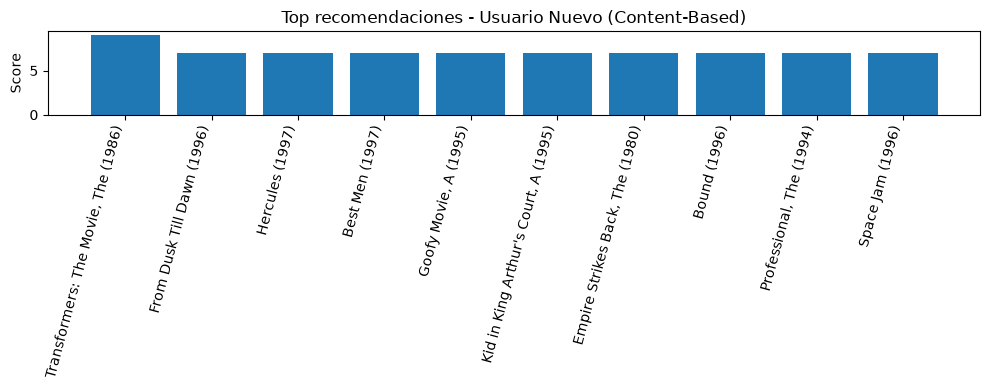

In [41]:
# ---------- Limpieza y reconstrucción de la matriz película x géneros ----------
import pandas as pd
import numpy as np

# 1) Forzar movie_id numérico y limpiar filas inválidas
movies_items['movie_id'] = pd.to_numeric(movies_items['movie_id'], errors='coerce')
movies_items = movies_items.dropna(subset=['movie_id']).copy()
movies_items['movie_id'] = movies_items['movie_id'].astype(int)

# 2) Asignar (o verificar) nombres de columnas si no los tienes. 
movies_cols = [
    'movie_id', 'title', 'release_date', 'video_release_date', 'imdb_url',
    'unknown','Action','Adventure','Animation',"Children's",'Comedy',
    'Crime','Documentary','Drama','Fantasy','Film-Noir','Horror',
    'Musical','Mystery','Romance','Sci-Fi','Thriller','War','Western'
]
if len(movies_items.columns) == len(movies_cols):
    movies_items.columns = movies_cols

# 3) Obtener las columnas de géneros a partir de movies_items
# (asumiendo que están exactamente después de imdb_url)
genre_cols = [c for c in movies_items.columns if c not in ['movie_id','title','release_date','video_release_date','imdb_url']]

# 4) Construir matrix película x género (index = movie_id)
movie_genres = movies_items.set_index('movie_id')[genre_cols].fillna(0).astype(float)

# Comprobaciones rápidas
print("movies_items shape:", movies_items.shape)
print("movie_genres shape:", movie_genres.shape)
print("Ejemplo genres cols:", genre_cols[:8])

# ---------- Función content-based para usuario nuevo ----------
def recommend_for_new_user(new_user_ratings, top_n=10, baseline=3.0):
    """
    new_user_ratings: lista de tuplas (movie_id, rating) que el usuario da
    baseline: puntuación de referencia (por ejemplo 3.0)
    Devuelve top_n recomendaciones (movie_id, title, score)
    """
    # Asegurar índices numéricos
    mg = movie_genres.copy()
    mg.index = mg.index.astype(int)
    M = mg.values                        # shape: (n_movies, n_genres)
    movie_ids = mg.index.values          # array de movie_id
    
    total_score = np.zeros(len(movie_ids))
    
    for mid, r in new_user_ratings:
        try:
            mid = int(mid)
        except:
            continue
        if mid in mg.index:
            vec = mg.loc[mid].values     # vector 0/1 de longitud n_genres
            # Similaridad simple: producto punto entre vectores de géneros
            sim = M.dot(vec)            # para cada película: cuántos géneros comparten con 'mid'
            total_score += (r - baseline) * sim
        else:
            # si la película no está en la matriz (id inválido), la ignoramos
            continue
    
    df = pd.DataFrame({'movie_id': movie_ids, 'score': total_score})
    # excluir vistas en new_user_ratings
    watched = set(int(x[0]) for x in new_user_ratings if str(x[0]).isdigit())
    df = df[~df['movie_id'].isin(watched)]
    
    # unir títulos (movies_items ya tiene movie_id int y title)
    df = df.merge(movies_items[['movie_id','title']], on='movie_id', how='left')
    df = df.sort_values('score', ascending=False).reset_index(drop=True)
    return df.head(top_n)

# ---------- Prueba con tu ejemplo ----------
sample_ratings_new = [(1,5),(50,4),(100,5)]
rec = recommend_for_new_user(sample_ratings_new, top_n=10)
display(rec)

# ---------- Plot de recomendaciones para usuario nuevo ----------
plt.figure(figsize=(10,4))
plt.bar(rec['title'], rec['score'])
plt.xticks(rotation=75, ha='right')
plt.title('Top recomendaciones - Usuario Nuevo (Content-Based)')
plt.ylabel('Score')
plt.tight_layout()
plt.show()


## Análisis

Las recomendaciones parecen surgir de géneros favoritos proporcionados por el usuario nuevo, mostrando que el sistema basado en contenido funciona bien para cold-start: utiliza géneros y metadatos para hacer predicciones iniciales sin historial.

## 5) Incorporar información demográfica y análisis de gustos
Construiremos perfiles por usuario sobre géneros (promedio ponderado) y analizaremos por edad/sexo/ocupación.

In [42]:
# ---------- Limpieza y reconstrucción de la matriz película x géneros ----------
import pandas as pd
import numpy as np

# 1) Forzar movie_id numérico y limpiar filas inválidas
movies_items['movie_id'] = pd.to_numeric(movies_items['movie_id'], errors='coerce')
movies_items = movies_items.dropna(subset=['movie_id']).copy()
movies_items['movie_id'] = movies_items['movie_id'].astype(int)

# 2) Asignar (o verificar) nombres de columnas si no los tienes
movies_cols = [
    'movie_id','title','release_date','video_release_date','imdb_url',
    'unknown','Action','Adventure','Animation',"Children's",'Comedy','Crime',
    'Documentary','Drama','Fantasy','Film-Noir','Horror','Musical','Mystery',
    'Romance','Sci-Fi','Thriller','War','Western'
]

if len(movies_items.columns) == len(movies_cols):
    movies_items.columns = movies_cols

# 3) Obtener columnas de géneros
genre_cols = [c for c in movies_items.columns 
              if c not in ['movie_id','title','release_date','video_release_date','imdb_url']]

# 4) Construir matriz película x géneros (index = movie_id)
movie_genres = movies_items.set_index('movie_id')[genre_cols].fillna(0).astype(float)

# Comprobaciones rápidas
print("movies_items shape:", movies_items.shape)
print("movie_genres shape:", movie_genres.shape)
print("Ejemplo genres cols:", genre_cols[:8])


# ---------- Función content-based para usuario nuevo ----------
def recommend_for_new_user(new_user_ratings, top_n=10, baseline=3.0):
    """
    new_user_ratings: lista de tuplas (movie_id, rating)
    baseline: puntuación de referencia (por ejemplo 3.0)
    Devuelve top_n recomendaciones (movie_id, title, score)
    """

    mg = movie_genres.copy()
    mg.index = mg.index.astype(int)

    M = mg.values                    # matriz (n_movies, n_genres)
    movie_ids = mg.index.values

    total_score = np.zeros(len(movie_ids))

    for mid, r in new_user_ratings:
        try:
            mid = int(mid)
        except:
            continue

        if mid in mg.index:
            vec = mg.loc[mid].values
            sim = M.dot(vec)                # similaridad simple vía producto punto
            total_score += (r - baseline) * sim
        else:
            continue

    df = pd.DataFrame({'movie_id': movie_ids, 'score': total_score})

    # excluir películas ya vistas
    watched = set(int(x[0]) for x in new_user_ratings if str(x[0]).isdigit())
    df = df[~df['movie_id'].isin(watched)]

    # agregar títulos
    df = df.merge(movies_items[['movie_id','title']], on='movie_id', how='left')

    df = df.sort_values('score', ascending=False).reset_index(drop=True)
    return df.head(top_n)


# ---------- Prueba con tu ejemplo ----------
sample_ratings_new = [(1,5), (50,4), (100,5)]
rec = recommend_for_new_user(sample_ratings_new, top_n=10)

display(rec)


movies_items shape: (1682, 24)
movie_genres shape: (1682, 19)
Ejemplo genres cols: ['unknown', 'Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime', 'Documentary']


,movie_id,score,title
0,426,9.0,"Transformers: The Movie, The (1986)"
1,17,7.0,From Dusk Till Dawn (1996)
2,993,7.0,Hercules (1997)
3,1138,7.0,Best Men (1997)
4,1219,7.0,"Goofy Movie, A (1995)"
5,560,7.0,"Kid in King Arthur's Court, A (1995)"
6,172,7.0,"Empire Strikes Back, The (1980)"
7,129,7.0,Bound (1996)
8,55,7.0,"Professional, The (1994)"
9,820,7.0,Space Jam (1996)


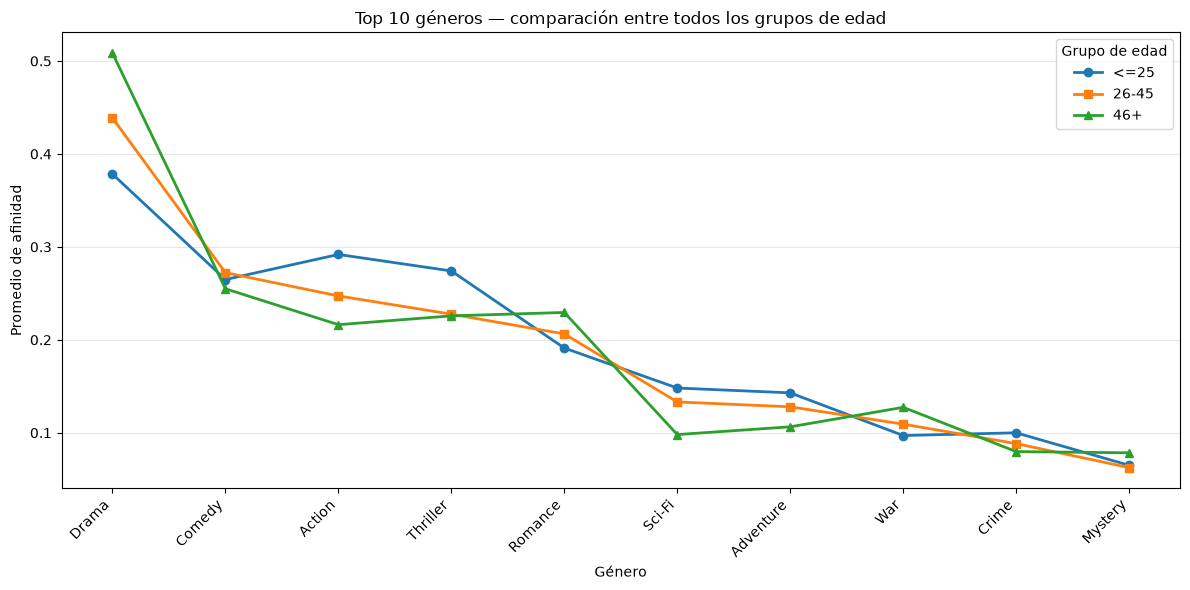

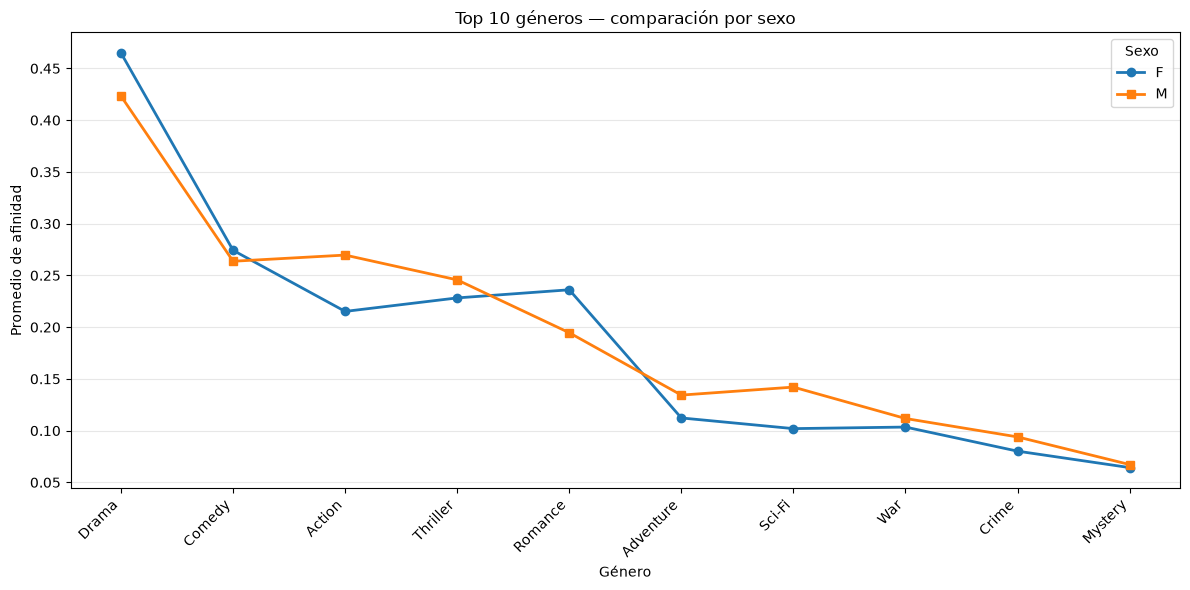

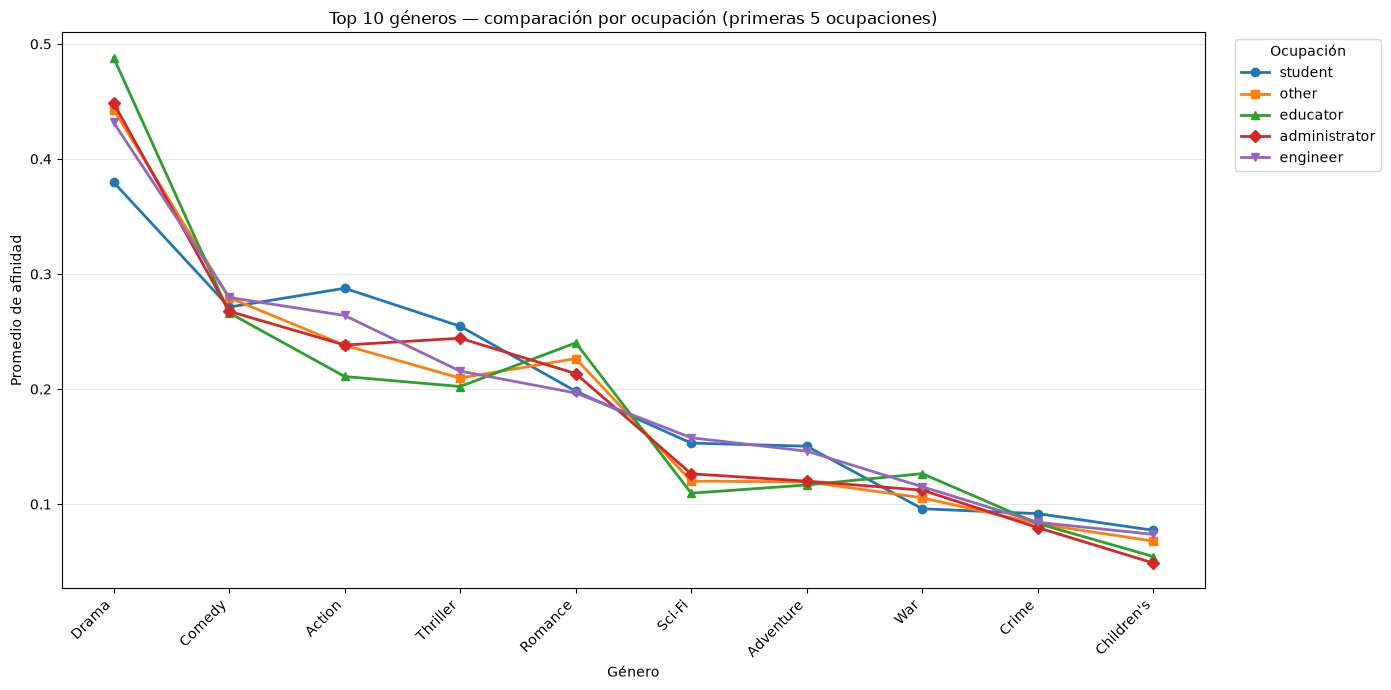

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# 0) Nombres/objetos: intentar usar users_demo si existe
# -----------------------------
if 'users_demo' not in globals() and 'users' in globals():
    users_demo = users.copy()

# -----------------------------
# 1) Construir / asegurar movie_genres y genre_cols
# -----------------------------
# Si movie_genres no existe, construirlo desde movies_items
if 'movie_genres' not in globals():
    # Asegurar movie_id int y encabezados (si movies_cols ya definidos, se respetan)
    movies_items['movie_id'] = pd.to_numeric(movies_items['movie_id'], errors='coerce')
    movies_items = movies_items.dropna(subset=['movie_id']).copy()
    movies_items['movie_id'] = movies_items['movie_id'].astype(int)
    # detectar columnas de géneros (asumimos que las 5 primeras no son géneros)
    non_genre = ['movie_id','title','release_date','video_release_date','imdb_url']
    genre_cols = [c for c in movies_items.columns if c not in non_genre]
    movie_genres = movies_items.set_index('movie_id')[genre_cols].fillna(0).astype(float)
else:
    # si existe, obtener genre_cols desde allí
    genre_cols = [c for c in movie_genres.columns]

# -----------------------------
# 2) Construir user_genre_profile (promedio ponderado por rating)
# -----------------------------
# Necesitamos ratings y movie_genres; si ratings no está, abortar con mensaje
if 'ratings' not in globals():
    raise RuntimeError("El DataFrame 'ratings' no está definido en el entorno. Carga primero los datos.")

# Merge ratings con movie_genres (reset_index para tener movie_id columna)
ratings_with_genres = ratings.merge(movie_genres.reset_index(), on='movie_id', how='left')

# Multiplicar cada género por el rating dado (contribución)
for g in genre_cols:
    ratings_with_genres[g] = ratings_with_genres[g].fillna(0) * ratings_with_genres['rating']

# user_genre_profile = suma (por usuario) de contribuciones por género / suma de ratings por usuario
user_sum_genre = ratings_with_genres.groupby('user_id')[genre_cols].sum()
user_sum_rating = ratings_with_genres.groupby('user_id')['rating'].sum().replace(0, np.nan)  # evitar división por 0
user_genre_profile = user_sum_genre.div(user_sum_rating, axis=0).fillna(0)

# -----------------------------
# 3) Merge seguro con demografía (users_demo)
# -----------------------------
# Normalizar users_demo columnas y tipos
ud = users_demo.copy() if 'users_demo' in globals() else (users.copy() if 'users' in globals() else None)
if ud is None:
    raise RuntimeError("No se encontró 'users_demo' ni 'users'. Carga el DataFrame de usuarios antes de ejecutar.")

# Normalizar nombre sexo
if 'gender' in ud.columns and 'sex' not in ud.columns:
    ud = ud.rename(columns={'gender':'sex'})

# Asegurar user_id como columna y tipo numérico
if 'user_id' not in ud.columns:
    ud = ud.rename(columns={ud.columns[0]:'user_id'})
ud['user_id'] = pd.to_numeric(ud['user_id'], errors='coerce')

# Resetear índice de perfil y forzar user_id numérico
ugp = user_genre_profile.reset_index().rename(columns={'index':'user_id'}) if 'user_id' not in user_genre_profile.columns else user_genre_profile.reset_index()
if 'user_id' not in ugp.columns:
    ugp = ugp.rename(columns={ugp.columns[0]:'user_id'})
ugp['user_id'] = pd.to_numeric(ugp['user_id'], errors='coerce')

# Merge final
uprof_demo = ugp.merge(ud, on='user_id', how='left')

# Forzar edad numérica y sexo en mayúscula si existe
if 'age' in uprof_demo.columns:
    uprof_demo['age'] = pd.to_numeric(uprof_demo['age'], errors='coerce')
if 'sex' in uprof_demo.columns:
    uprof_demo['sex'] = uprof_demo['sex'].astype(str).str.upper().replace({'M':'M','F':'F'})

# -----------------------------
# 4) Crear agrupaciones y agregados necesarios
# -----------------------------
# a) Grupos de edad (usar bins estándar; ajusta si quieres otra partición)
bins = [0, 25, 45, 120]
labels = ['<=25', '26-45', '46+']
uprof_demo['age_group'] = pd.cut(uprof_demo['age'], bins=bins, labels=labels, include_lowest=True)

# b) Agregados: media por grupo de edad y por sexo
age_group_mean = uprof_demo.groupby('age_group')[genre_cols].mean().T   # filas=generos, cols=age groups
# Si hay grupos vacíos, eliminarlos
age_group_mean = age_group_mean.loc[:, [c for c in age_group_mean.columns if c in labels]]

sex_col = 'sex' if 'sex' in uprof_demo.columns else None
if sex_col:
    gender_mean = uprof_demo.groupby(sex_col)[genre_cols].mean().T   # filas=generos, cols=sex values
else:
    gender_mean = None

# c) Ocupaciones: tomar las 5 ocupaciones más frecuentes y calcular medias
occ_counts = uprof_demo['occupation'].value_counts(dropna=True)
top5_occ = occ_counts.head(5).index.tolist()
if len(top5_occ) > 0:
    occ_mean = uprof_demo.groupby('occupation')[genre_cols].mean().loc[top5_occ].T
else:
    occ_mean = None

# -----------------------------
# 5) PLOTs: todos líneas con markers
# -----------------------------
# Helper: style settings
plt.rcParams.update({'figure.autolayout': False})
marker_list = ['o','s','^','D','v','<','>','P','X','*']  # markers para las series

# --- 1) Todos los grupos de edad en un solo plot (líneas con markers) ---
if not age_group_mean.empty:
    plt.figure(figsize=(12,6))
    cols = age_group_mean.columns.tolist()
    for i, grp in enumerate(cols):
        vals = age_group_mean[grp].sort_values(ascending=False)  # orden para visual (opcional)
        # Para mantener eje x consistente entre series, necesitamos plotear usando genre index
        # pero mantener el mismo orden: usaremos el orden de genre_cols
    # En lugar de ordenar por cada serie, mostramos top 10 géneros globalmente para legibilidad:
    # calcular top 10 géneros por promedia en todos los grupos
    top10_genres = age_group_mean.mean(axis=1).sort_values(ascending=False).head(10).index.tolist()

    x = np.arange(len(top10_genres))
    for i, grp in enumerate(cols):
        y = age_group_mean.loc[top10_genres, grp].values
        m = marker_list[i % len(marker_list)]
        plt.plot(x, y, marker=m, label=str(grp), linewidth=2)

    plt.xticks(x, top10_genres, rotation=45, ha='right')
    plt.title("Top 10 géneros — comparación entre todos los grupos de edad")
    plt.ylabel("Promedio de afinidad")
    plt.xlabel("Género")
    plt.legend(title="Grupo de edad")
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No hay datos para age_group_mean (falta la columna 'age' o no hay usuarios asignados a grupos).")

# --- 2) Top géneros por sexo (líneas con markers) ---
if gender_mean is not None and not gender_mean.empty:
    # elegir top 10 géneros por media global de ambos sexos
    top10_genres_g = gender_mean.mean(axis=1).sort_values(ascending=False).head(10).index.tolist()
    x = np.arange(len(top10_genres_g))
    plt.figure(figsize=(12,6))
    for i, s in enumerate(gender_mean.columns):
        y = gender_mean.loc[top10_genres_g, s].values
        m = marker_list[i % len(marker_list)]
        plt.plot(x, y, marker=m, label=str(s), linewidth=2)
    plt.xticks(x, top10_genres_g, rotation=45, ha='right')
    plt.title("Top 10 géneros — comparación por sexo")
    plt.ylabel("Promedio de afinidad")
    plt.xlabel("Género")
    plt.legend(title="Sexo")
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No hay datos para gender_mean (falta columna 'sex' en users).")

# --- 3) Top 10 géneros de las 5 primeras ocupaciones (líneas con markers) ---
if occ_mean is not None and not occ_mean.empty:
    top10_genres_occ = occ_mean.mean(axis=1).sort_values(ascending=False).head(10).index.tolist()
    x = np.arange(len(top10_genres_occ))
    plt.figure(figsize=(14,7))
    for i, occ in enumerate(occ_mean.columns):
        y = occ_mean.loc[top10_genres_occ, occ].values
        m = marker_list[i % len(marker_list)]
        plt.plot(x, y, marker=m, label=str(occ), linewidth=2)
    plt.xticks(x, top10_genres_occ, rotation=45, ha='right')
    plt.title("Top 10 géneros — comparación por ocupación (primeras 5 ocupaciones)")
    plt.ylabel("Promedio de afinidad")
    plt.xlabel("Género")
    plt.legend(title="Ocupación", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No hay suficientes datos de ocupación para graficar.")


## Análisis

### 1. Diferencias por grupo de edad

Los promedios por género muestran que los patrones de consumo son muy similares entre edades, pero hay matices:
En todos los grupos, Drama, Comedy y Action son consistentemente los géneros más vistos.
El grupo 46+ muestra un ligero aumento en:
- War, Thriller y Crime, géneros algo más "serios" o clásicos.
- El grupo <=25 tiene proporciones un poco menores en estos géneros y se mantiene cercano al promedio general.
- El grupo 26–45 queda prácticamente en el medio, con preferencias más equilibradas.

Conclusión:
No existen separaciones fuertes por edad, pero los mayores tienden a inclinarse ligeramente por géneros más densos o clásicos, mientras que los más jóvenes muestran proporciones ligeramente más bajas en esos géneros.

### 2. Diferencias por sexo

La diferencia entre hombres (M) y mujeres (F) sigue siendo sutil, pero con algunos patrones:
- Drama es el género más consumido por ambos; ligeramente mayor en mujeres.
- Action y Thriller son marginalmente más populares en hombres.
- Comedy está algo más presente en mujeres.
- Para géneros como Sci-Fi, Adventure, Crime o Mystery, prácticamente no hay diferencias.

Conclusión:
El comportamiento por sexo es prácticamente homogéneo, con micro-variaciones que pueden usarse para ajustar un modelo híbrido, pero no como fuente principal de segmentación.

### 3. Diferencias por ocupación

Aquí sí aparecen diferencias más interesantes:

**Administradores, educadores e ingenieros muestran patrones similares:**
- Alto consumo de Drama, Comedy, Action, Thriller.

**Artistas muestran:**
- Más interés relativo en Comedy, Drama, Musical, Animation.
- Menor afinidad por Sci-Fi y War.

**Doctores destacan por:**
- Alto peso en Drama (mayor que cualquier otro grupo).
- Bajos valores en Sci-Fi y Adventure.

Conclusión:
La ocupación parece ser un factor más diferenciador que edad o sexo.
Ocupaciones “creativas” (artistas) consumen géneros más suaves o expresivos; ocupaciones técnicas o administrativas mantienen patrones más estándar. Profesiones más intensivas (como medicina) tienden a géneros serios como Drama.

---

# 6. Métodos utilizados y forma de aplicación

A continuación se describen los métodos aplicados en cada etapa del taller y cómo fueron utilizados dentro del flujo del proyecto:

**1. Análisis Exploratorio de Datos (EDA)**  
- Se emplearon métodos descriptivos (conteos, promedios, proporciones) para entender la distribución de ratings, usuarios, películas y el nivel de sparsity de la matriz.  
- Se usaron agrupamientos groupby para identificar las películas más populares y las mejor calificadas.  
- Las tablas generadas permitieron comprender tendencias globales y sesgos del dataset.

**2. Construcción de la matriz usuario–ítem y preparación de datos**  
- Se utilizó un *pivot table* para crear la matriz user_item, dejando filas como user_id y columnas como movie_id.  
- Se empleó relleno con 0 o NaN según la etapa, permitiendo diferenciar entre “no rating” y “rating real”.

**3. Modelos no supervisados (PCA + K-Means)**  
- **PCA (Análisis de Componentes Principales)**:  
  - Se aplicó para reducir la dimensionalidad de la matriz usuario–género y capturar las variaciones principales.  
  - Se analizaron las componentes principales mediante el *explained variance ratio*, evidenciando cuánto de la varianza explicaba cada una.
- **K-Means**:  
  - Se utilizó para agrupar usuarios según sus patrones de consumo cinematográfico.  
  - Se analizaron estadísticas por cluster (edad media, proporción de mujeres, géneros preferidos).

**4. Sistema de recomendación item-based (Filtrado colaborativo basado en ítems)**  
- Se construyó una matriz ítem–usuario y se calculó la **similitud coseno** entre ítems.  
- Para cada usuario, la recomendación se generó como una suma ponderada de similitudes con los ítems ya calificados, ajustando por un valor base (ej. rating − 3).  
- Se excluyeron las películas ya vistas y se retornó el top-N de mayor puntaje.

**5. Evaluación del recomendador**  
- Se realizó un split train/test.  
- Se calculó el RMSE para medir qué tan cerca estaba el modelo de los ratings reales.  
- El RMSE ~1.01 indica un desempeño razonable dentro de los métodos colaborativos simples.

**6. Manejo de cold-start (usuarios nuevos)**  
- Se empleó información de géneros preferidos para recomendar películas basadas en similitud de contenido.  
- Se generó un perfil inicial basado en selección de géneros para calcular un score por contenido.

**7. Incorporación de información demográfica**  
- Se calcularon promedios de preferencia de género usando cruces por edad, sexo y ocupación.  
- Estos perfiles permiten ajustar recomendaciones tomando en cuenta patrones demográficos adicionales.


---

# 7. Discusión del desarrollo, métodos y posibles mejoras

El desarrollo del proyecto mostró cómo combinar análisis exploratorio, métodos no supervisados y sistemas de recomendación para obtener una visión integral del comportamiento de los usuarios y de la dinámica del sistema.

- **Sobre el EDA:** permitió detectar patrones claves como alta sparsity y sesgos hacia ciertos géneros y películas populares.  
- **Sobre PCA + K-Means:** si bien las primeras 10 componentes solo explican ~28% de la varianza, los clusters detectaron diferencias interesantes en edad y preferencias de género. Esto indica que los gustos son diversos y la estructura latente es compleja.  
- **Sobre el recomendador item-based:** funcionó bien para usuarios con suficiente historial, entregando recomendaciones coherentes. Sin embargo, el enfoque basado únicamente en similitud coseno es limitado frente a modelos más avanzados como *matrix factorization* o *deep learning*.  
- **Sobre el cold-start:** la estrategia basada en contenido resolvió parcialmente el problema, pero podría enriquecerse usando embeddings de texto o modelos de contenido más ricos.  
- **Sobre la evaluación:** un RMSE cercano a 1 es común en modelos simples; aún así, existe margen para mejorar mediante regularización, ajustes de hiperparámetros o modelos híbridos.  
- **Integración de información demográfica:** añadió una capa adicional que permite personalizar recomendaciones iniciales, aunque su poder predictivo suele ser limitado en comparación con el historial de comportamiento.

**Posibles mejoras futuras:**
- Implementar *matrix factorization* (SVD, ALS).  
- Construir un modelo híbrido que combine contenido + colaborativo + demografía.  
- Utilizar embeddings de películas (descripciones, sinopsis, género más detallado).  
- Evaluar con métricas centradas en ranking (NDCG, MAP) además del RMSE.  
- Incluir técnicas avanzadas como modelos secuenciales (RNNs, transformers) para capturar patrones temporales.

En conjunto, el proyecto demuestra el flujo completo de análisis y construcción de un sistema de recomendación funcional, señalando áreas claras para mejorar y escalar a sistemas más sofisticados.
